# Day 33 — Drawing the Best Line
## Simple linear regression, built from scratch

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

Today you build a model. Not read about one — build one, by hand, on five students,
with numbers small enough to check in your head.

| Part | What we do |
|---|---|
| **1** | Five students, one question, and what a line actually is |
| **2** | How wrong is a line? Turning "best" into a number |
| **3** | Two ways to find the best line — a formula, and walking downhill |
| **4** | Reading the model: the slope, the intercept, R², and the errors |
| **5** | Doing it for real: scikit-learn, 60 students, and one trap |

### Before you start

Run the cell below. Then read each cell, **predict what it will print**, and only then
run it. You will learn five times as much that way.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["font.size"] = 11

print("ready")

ready


---
# Part 1 · What a line is for

## 1.1 · Five students

You asked five classmates two questions: how many hours a week do you study, and what
did you score?

In [2]:
hours = np.array([1., 2, 3, 4, 5])
marks = np.array([34., 44, 47, 58, 67])

students = pd.DataFrame({"hours": hours, "marks": marks})
students

,hours,marks
0,1.0,34.0
1,2.0,44.0
2,3.0,47.0
3,4.0,58.0
4,5.0,67.0


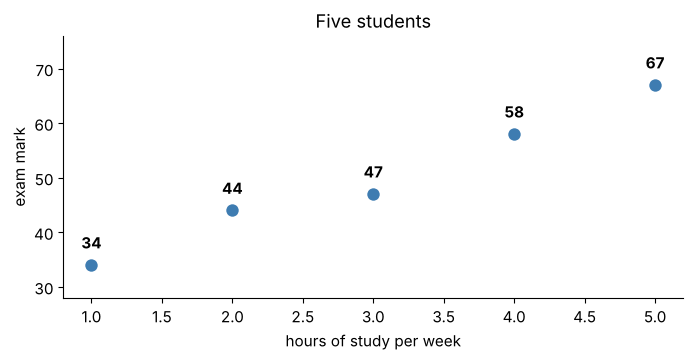

In [3]:
plt.scatter(hours, marks, s=120, color="#3E7CB1", zorder=5, edgecolor="white", lw=2)
for h, m in zip(hours, marks):
    plt.annotate(f"{m:.0f}", (h, m), xytext=(0, 12), textcoords="offset points",
                 ha="center", fontweight="bold")
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title("Five students")
plt.ylim(28, 76)
plt.show()

### The question

**A new student studies 6 hours a week. What will she score?**

She is not in the table. You cannot look her up. You need a **rule** — something that
turns *any* number of hours into a mark.

## 1.2 · A line is that rule

A straight line is the simplest rule there is:

```
mark  =  slope × hours  +  intercept
```

Two numbers, and the rule is complete. Let us try `slope = 8` and `intercept = 26` —
in a moment we will see where those came from.

In [3]:
def line(h, slope, intercept):
    """Our model. Give it hours, it gives back a predicted mark."""
    return slope * h + intercept

print("a student doing 6 hours :", line(6, 8, 26), "marks")
print("a student doing 2 hours :", line(2, 8, 26), "marks")
print("a student doing 7.5 hrs :", line(7.5, 8, 26), "marks")

a student doing 6 hours : 74 marks
a student doing 2 hours : 42 marks
a student doing 7.5 hrs : 86.0 marks


Notice what just happened. **The rule answered for students who were never in the table.**

And notice what the rule does *not* contain: it does not store the five students. It
stores **two numbers**. That is the whole model.

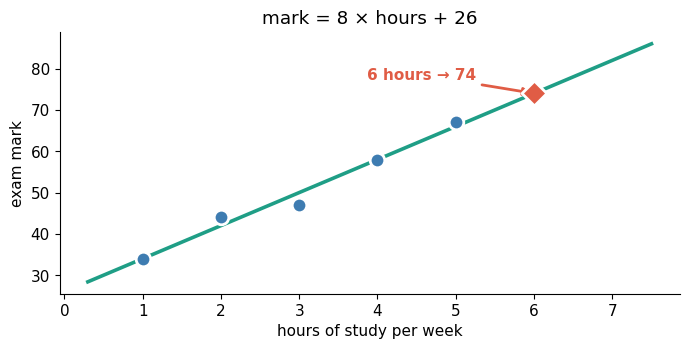

In [4]:
grid = np.linspace(0.3, 7.5, 60)

plt.scatter(hours, marks, s=110, color="#3E7CB1", zorder=5, edgecolor="white", lw=2)
plt.plot(grid, line(grid, 8, 26), color="#1F9E86", lw=2.6)
plt.scatter([6], [line(6, 8, 26)], s=160, color="#E05C45", zorder=6, marker="D",
            edgecolor="white", lw=2)
plt.annotate("6 hours → 74", (6, 74), xytext=(-120, 10), textcoords="offset points",
             color="#E05C45", fontweight="bold",
             arrowprops=dict(arrowstyle="-|>", color="#E05C45", lw=2))
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title("mark = 8 × hours + 26")
plt.show()

## 1.3 · What the two numbers mean

| | In the formula | In English |
|---|---|---|
| **slope** | 8 | one extra hour of study a week is worth about **8 more marks** |
| **intercept** | 26 | the line's answer at **zero hours** |

Check the slope claim yourself — it is just subtraction:

In [5]:
print("at 3 hours the line says:", line(3, 8, 26))
print("at 4 hours the line says:", line(4, 8, 26))
print("the difference          :", line(4, 8, 26) - line(3, 8, 26))
print()
print("at 9 hours the line says:", line(9, 8, 26))
print("at 10 hours             :", line(10, 8, 26))
print("the difference          :", line(10, 8, 26) - line(9, 8, 26))
print()
print("The gap is 8 EVERYWHERE. That is what 'straight' means.")

at 3 hours the line says: 50
at 4 hours the line says: 58
the difference          : 8

at 9 hours the line says: 98
at 10 hours             : 106
the difference          : 8

The gap is 8 EVERYWHERE. That is what 'straight' means.


## 1.4 · But why those two numbers?

I pulled 8 and 26 out of the air. Here are two other lines that also pass through the
middle of the dots.

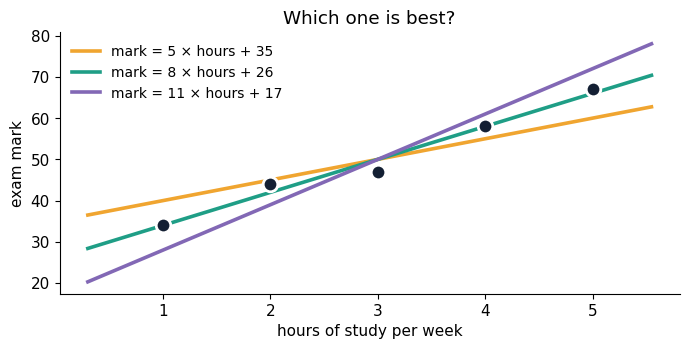

In [6]:
plt.scatter(hours, marks, s=110, color="#131F33", zorder=6, edgecolor="white", lw=2)
for sl, ic, c in [(5, 35, "#F0A530"), (8, 26, "#1F9E86"), (11, 17, "#8268B5")]:
    plt.plot(grid[grid <= 5.6], line(grid[grid <= 5.6], sl, ic), lw=2.6, color=c,
             label=f"mark = {sl} × hours + {ic}")
plt.legend(frameon=False, fontsize=10)
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title("Which one is best?")
plt.show()

**They cannot all be best.** But to pick one, we first have to agree on what "best" means
— and it has to be something we can *compute*, not something we argue about.

That is the whole of Part 2.

---
# Part 2 · How wrong is a line?

## 2.1 · The error on one student

Take the student who studied 5 hours and scored 67. What does the amber line
(`5 × hours + 35`) say about him?

In [7]:
actual = 67
guess  = line(5, 5, 35)

print("he actually got     :", actual)
print("the line predicted  :", guess)
print("error = actual − line:", actual - guess)

he actually got     : 67
the line predicted  : 60
error = actual − line: 7


That is all an error is: **the gap between the dot and the line.**

We always write it **actual − line**, in that order, so that:

- a **positive** error means the line guessed **too low**
- a **negative** error means the line guessed **too high**

Be consistent about the order, or the signs will confuse you later.

## 2.2 · The obvious idea: add the errors up

Let us score the good line by adding up all five errors.

In [ ]:
good_errors = marks - line(hours, 8, 26)

print("errors:", good_errors)
print("added up:", good_errors.sum())

errors: [ 0.  2. -3.  0.  1.]
added up: 0.0


Zero. Which sounds perfect — until you try it on the worst line imaginable.

In [9]:
# a line sloping the WRONG WAY: more study, fewer marks
upside_down = marks - line(hours, -8, 74)

print("the upside-down line's errors:", upside_down)
print("added up                     :", upside_down.sum())

the upside-down line's errors: [-32. -14.  -3.  16.  33.]
added up                     : 0.0


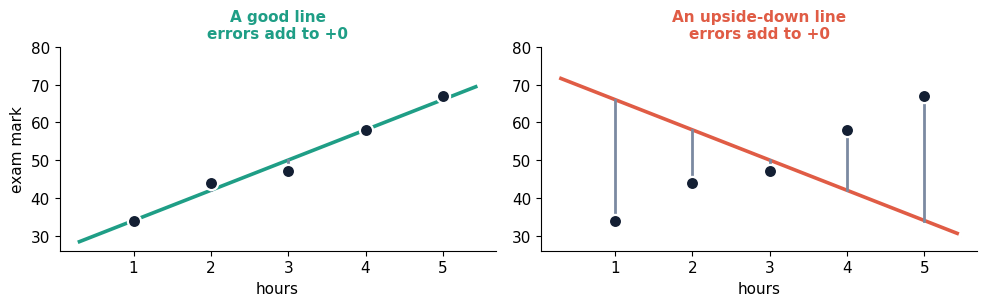

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (sl, ic, ttl, c) in zip(axes, [(8, 26, "A good line", "#1F9E86"),
                                       (-8, 74, "An upside-down line", "#E05C45")]):
    ax.plot(grid[grid <= 5.5], line(grid[grid <= 5.5], sl, ic), color=c, lw=2.6)
    for h, m in zip(hours, marks):
        ax.plot([h, h], [m, line(h, sl, ic)], color="#7B8AA1", lw=2)
    ax.scatter(hours, marks, s=90, color="#131F33", zorder=6, edgecolor="white", lw=1.6)
    ax.set_title(f"{ttl}\nerrors add to {(marks - line(hours, sl, ic)).sum():+.0f}",
                 color=c, fontweight="bold", fontsize=11)
    ax.set_xlabel("hours")
    ax.set_ylim(26, 80)
axes[0].set_ylabel("exam mark")
plt.tight_layout(); plt.show()

### Both score zero

The best line we have and the exactly-backwards line get **the same score**.

The reason is simple: the pluses and the minuses cancel. A line that is wildly too high
for half the students and wildly too low for the other half adds up to zero, and the
score tells you nothing at all.

**So adding the errors is useless.** We need something that cannot cancel.

## 2.3 · Square them first

In [12]:
table = pd.DataFrame({
    "hours":        hours,
    "actual mark":  marks,
    "the line says": line(hours, 8, 26),
    "error":        marks - line(hours, 8, 26),
})
table["error squared"] = table["error"] ** 2
table

,hours,actual mark,the line says,error,error squared
0,1.0,34.0,34.0,0.0,0.0
1,2.0,44.0,42.0,2.0,4.0
2,3.0,47.0,50.0,-3.0,9.0
3,4.0,58.0,58.0,0.0,0.0
4,5.0,67.0,66.0,1.0,1.0


In [13]:
print("errors added up      :", table["error"].sum(), "   <- useless")
print("squared errors added :", table["error squared"].sum(), "  <- this one works")

errors added up      : 0.0    <- useless
squared errors added : 14.0   <- this one works


Squaring throws away the sign. A miss of −3 and a miss of +3 both cost 9, so they can
never cancel.

**Now "best" has a definition:**

> The best line is the one with the **smallest total squared error**.

That is where the name **least squares** comes from — and it is not a metaphor.

## 2.4 · The squares are real squares

In [14]:
def sse(slope, intercept):
    """Total squared error for this line, on our five students."""
    return float(((marks - line(hours, slope, intercept)) ** 2).sum())

for sl, ic in [(5, 35), (8, 26), (11, 17), (-8, 74)]:
    print(f"mark = {sl:>3} × hours + {ic:<3}  ->  total squared error = {sse(sl, ic):>7.0f}")

mark =   5 × hours + 35   ->  total squared error =     104
mark =   8 × hours + 26   ->  total squared error =      14
mark =  11 × hours + 17   ->  total squared error =     104
mark =  -8 × hours + 74   ->  total squared error =    2574


There it is, as a single number per line. The teal line wins, and the upside-down line
is 184 times worse than it.

## 2.5 · Why square, rather than just ignore the sign?

Both remove the sign. But squaring says something extra: **one enormous miss is worse
than several small ones.**

In [15]:
five_small = np.array([2., 2, 2, 2, 2])
one_big    = np.array([10., 0, 0, 0, 0])

print("            ignoring the sign   squaring")
print(f"five small misses  {np.abs(five_small).sum():>8.0f}       {(five_small**2).sum():>8.0f}")
print(f"one big miss       {np.abs(one_big).sum():>8.0f}       {(one_big**2).sum():>8.0f}")

            ignoring the sign   squaring
five small misses        10             20
one big miss             10            100


Ignoring the sign calls them equally bad. Squaring says the single 10-mark blunder is
**five times worse**.

For predicting a mark, that is the judgement we want: a model that is usually within 2
and occasionally out by 30 is worse than one that is always out by 5.

*(There is a method that just ignores the sign — it is called MAE, and we use it for
**reporting** later in this notebook. For **fitting**, squares win, partly for this
reason and partly because they are smooth and easy to minimise.)*

---
# Part 3 · Finding the best line

We have a score. Now: which slope and intercept make it smallest?

## 3.1 · Try every slope and look

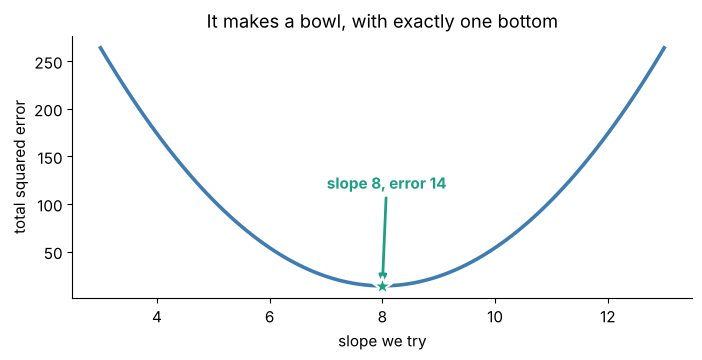

In [16]:
# for each slope, use the intercept that forces the line through the average point
# (average hours = 3, average marks = 50)
slopes = np.linspace(3, 13, 101)
errors = [sse(s, 50 - s*3) for s in slopes]

plt.plot(slopes, errors, lw=2.6, color="#3E7CB1")
plt.scatter([8], [sse(8, 26)], s=200, color="#1F9E86", zorder=6, marker="*",
            edgecolor="white", lw=1.5)
plt.annotate("slope 8, error 14", (8, 14), xytext=(-40, 70), textcoords="offset points",
             color="#1F9E86", fontweight="bold",
             arrowprops=dict(arrowstyle="-|>", color="#1F9E86", lw=2))
plt.xlabel("slope we try"); plt.ylabel("total squared error")
plt.title("It makes a bowl, with exactly one bottom")
plt.show()

In [17]:
for s in [4, 6, 8, 10, 12]:
    print(f"slope {s:>3}  ->  total squared error {sse(s, 50 - s*3):>6.0f}")

slope   4  ->  total squared error    174
slope   6  ->  total squared error     54
slope   8  ->  total squared error     14
slope  10  ->  total squared error     54
slope  12  ->  total squared error    174


Look at the symmetry: slope 6 and slope 10 both give 54. Slope 4 and slope 12 both give
174. The bowl is perfectly balanced around **8**.

**One bottom, no other dips.** For a straight line this is always true, and it is the
reason this problem is solvable at all. (It stops being true for bigger models — that is
when things get hard.)

## 3.2 · Route 1 · There is a formula

For a straight line we do not have to search. There is an exact formula:

```
slope  =  sum of (hours − average hours) × (mark − average mark)
              ÷  sum of (hours − average hours)²
```

Let us build it column by column, so nothing is magic.

In [18]:
avg_hours = hours.mean()
avg_marks = marks.mean()

print("average hours:", avg_hours)
print("average marks:", avg_marks)

work = pd.DataFrame({
    "hours":      hours,
    "mark":       marks,
    "hours − 3":  hours - avg_hours,
    "mark − 50":  marks - avg_marks,
})
work["multiply"]    = work["hours − 3"] * work["mark − 50"]
work["(hours−3)²"]  = work["hours − 3"] ** 2
work

average hours: 3.0
average marks: 50.0


,hours,mark,hours − 3,mark − 50,multiply,(hours−3)²
0,1.0,34.0,-2.0,-16.0,32.0,4.0
1,2.0,44.0,-1.0,-6.0,6.0,1.0
2,3.0,47.0,0.0,-3.0,-0.0,0.0
3,4.0,58.0,1.0,8.0,8.0,1.0
4,5.0,67.0,2.0,17.0,34.0,4.0


In [19]:
top    = work["multiply"].sum()
bottom = work["(hours−3)²"].sum()

print("top    =", top)
print("bottom =", bottom)
print()
print("slope     =", top, "/", bottom, "=", top / bottom)
print("intercept =", avg_marks, "−", top/bottom, "×", avg_hours, "=",
      avg_marks - (top/bottom) * avg_hours)

top    = 80.0
bottom = 10.0

slope     = 80.0 / 10.0 = 8.0
intercept = 50.0 − 8.0 × 3.0 = 26.0


### `mark = 8 × hours + 26`

The two numbers we have been using all along.

**Where does the intercept come from?** The best line is always forced through the
average point — 3 hours, 50 marks. Once you know the slope, the intercept is whatever it
has to be to pass through there. No searching required.

## 3.3 · Route 2 · Guess, then walk downhill

The formula is lovely, and it only exists because a straight line is simple. A neural
network has millions of numbers to choose and no formula at all.

So here is the method that *does* scale, called **gradient descent**:

1. Start with any slope and intercept. Zero and zero will do.
2. Work out the total squared error.
3. Nudge both numbers in whatever direction makes the error smaller.
4. Repeat.

### One step, slowly

Start at slope 0, intercept 0 — a flat line along the bottom.

In [20]:
slope, intercept = 0.0, 0.0
n = len(hours)

errors_now = line(hours, slope, intercept) - marks      # note: LINE − actual here
print("the line predicts:", line(hours, slope, intercept))
print("they actually got:", marks)
print("line − actual    :", errors_now)
print()

slope_nudge     = (2/n) * (errors_now * hours).sum()
intercept_nudge = (2/n) * errors_now.sum()

print("slope nudge     = (2/5) ×", (errors_now * hours).sum(), "=", slope_nudge)
print("intercept nudge = (2/5) ×", errors_now.sum(), "=", intercept_nudge)

the line predicts: [0. 0. 0. 0. 0.]
they actually got: [34. 44. 47. 58. 67.]
line − actual    : [-34. -44. -47. -58. -67.]

slope nudge     = (2/5) × -830.0 = -332.0
intercept nudge = (2/5) × -250.0 = -100.0


Both nudges are **negative**, which is the method telling us: *both numbers are too
small, make them bigger.*

Now take a small step **against** each nudge. How small is set by the **learning rate** —
we will use 0.03.

In [21]:
rate = 0.03

slope     = slope     - rate * slope_nudge
intercept = intercept - rate * intercept_nudge

print("new slope     :", round(slope, 4))
print("new intercept :", round(intercept, 4))
print()
print("total squared error before :", sse(0, 0))
print("total squared error after  :", round(sse(slope, intercept), 1))

new slope     : 9.96
new intercept : 3.0

total squared error before : 13154.0
total squared error after  : 1517.9


**One step, and the error fell from 13,154 to about 1,518.** Nothing clever happened —
we just moved in the direction that helped.

### Now run it a few thousand times

In [22]:
def gradient_descent(rate=0.03, steps=2000, show=(1, 2, 5, 20, 100, 500, 1500)):
    slope, intercept = 0.0, 0.0
    n = len(hours)
    history = []
    print(f"{'step':>6}{'slope':>9}{'intercept':>11}{'total squared error':>22}")
    print("-" * 48)
    for step in range(1, steps + 1):
        e = line(hours, slope, intercept) - marks
        slope     -= rate * (2/n) * (e * hours).sum()
        intercept -= rate * (2/n) * e.sum()
        history.append((slope, intercept, sse(slope, intercept)))
        if step in show:
            print(f"{step:>6}{slope:>9.2f}{intercept:>11.2f}{sse(slope, intercept):>22.1f}")
    return slope, intercept, history

final_slope, final_intercept, history = gradient_descent()
print()
print("landed on slope", round(final_slope, 4), "and intercept", round(final_intercept, 4))

  step    slope  intercept   total squared error
------------------------------------------------
     1     9.96       3.00                1517.9
     2    12.81       4.03                 530.3
     5    13.79       5.00                 415.1
    20    12.99       7.98                 309.4
   100    10.21      18.03                  71.8
   500     8.04      25.86                  14.0
  1500     8.00      26.00                  14.0

landed on slope 8.0 and intercept 26.0


### Two things worth noticing

**The slope overshoots.** It climbs to 13.79 by step 5 and then comes back down to 8.
Gradient descent does not glide gracefully to the answer — it lurches.

**But the error only ever goes down.** Watch that column, not the slope. 1518 → 530 → 415
→ 309 → 72 → 14. It never rises.

That is the honest picture of how these methods behave, and it is why you always track
the error rather than the parameters.

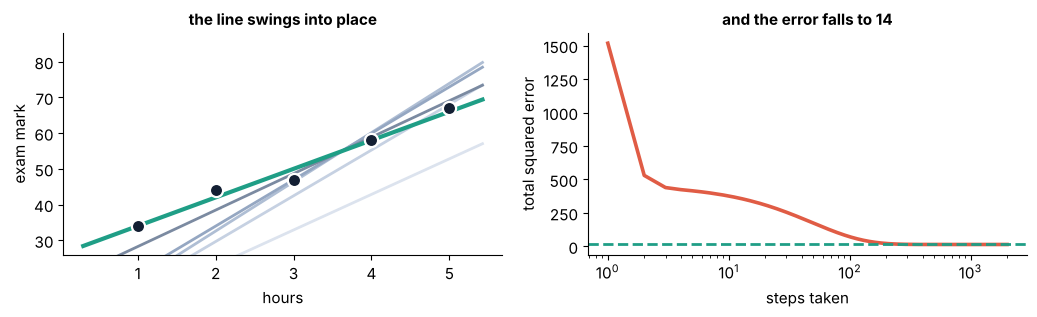

In [23]:
steps_shown = [1, 2, 5, 20, 100]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.3))

greys = ["#DCE3EE", "#C6D1E2", "#AFBED4", "#95A7C2", "#7B8AA1"]
for i, st in enumerate(steps_shown):
    sl, ic, _ = history[st - 1]
    axes[0].plot(grid[grid <= 5.5], line(grid[grid <= 5.5], sl, ic), color=greys[i], lw=2)
axes[0].plot(grid[grid <= 5.5], line(grid[grid <= 5.5], final_slope, final_intercept),
             color="#1F9E86", lw=3)
axes[0].scatter(hours, marks, s=90, color="#131F33", zorder=6, edgecolor="white", lw=1.6)
axes[0].set_ylim(26, 88); axes[0].set_xlabel("hours"); axes[0].set_ylabel("exam mark")
axes[0].set_title("the line swings into place", fontweight="bold", fontsize=11)

axes[1].plot(range(1, len(history) + 1), [h[2] for h in history], color="#E05C45", lw=2.6)
axes[1].axhline(14, color="#1F9E86", lw=2, ls="--")
axes[1].set_xscale("log")
axes[1].set_xlabel("steps taken"); axes[1].set_ylabel("total squared error")
axes[1].set_title("and the error falls to 14", fontweight="bold", fontsize=11)
plt.tight_layout(); plt.show()

## 3.4 · Same answer, both ways

| | slope | intercept | how long |
|---|---|---|---|
| the formula | 8.0 | 26.0 | one calculation |
| gradient descent | 8.0 | 26.0 | about 800 steps |

They agree because **there is only one bottom to the bowl**. Any method that goes
downhill and does not stop early must end up in the same place.

**Learn gradient descent properly.** The formula is a shortcut that happens to exist for
straight lines. Walking downhill is how essentially every modern model is trained,
including the ones behind the chatbots you use.

---
# Part 4 · Reading the model

A line you cannot explain in a sentence is not worth having.

## 4.1 · Say the slope out loud

In [24]:
print(f"mark = {final_slope:.0f} × hours + {final_intercept:.0f}")
print()
print(f'"One extra hour of study a week is worth about {final_slope:.0f} more marks."')

mark = 8 × hours + 26

"One extra hour of study a week is worth about 8 more marks."


That sentence is the whole reason anyone fits a line instead of a black box. If you
cannot finish *"one more unit of X is worth ___ of Y"*, you have not understood your own
model yet.

### The intercept needs more care

The intercept says: *a student who studies zero hours would score 26.*

That is true **of the line**. But look at the data — **nobody studied zero hours.** The
lowest was 1. So 26 is the line being extended into territory it never saw, and you
should not quote it as if it were a finding.

In [25]:
print("hours in our data run from", hours.min(), "to", hours.max())
print("the intercept describes hours =", 0, "<- outside that range")

hours in our data run from 1.0 to 5.0
the intercept describes hours = 0 <- outside that range


## 4.2 · R² — compared with just guessing the average

Our total squared error is 14. Is that good? **Fourteen compared to what?**

Here is the honest comparison: what if we had no model at all, and just said "50" for
every student?

In [26]:
flat_guess = np.full_like(marks, marks.mean())

error_flat = ((marks - flat_guess) ** 2).sum()
error_line = ((marks - line(hours, 8, 26)) ** 2).sum()

print("always guessing the average, 50 :", error_flat)
print("using our line                  :", error_line)
print()
print("R² = 1 −", error_line, "/", error_flat, "=", round(1 - error_line/error_flat, 4))
print()
print("sklearn agrees:", round(r2_score(marks, line(hours, 8, 26)), 4))

always guessing the average, 50 : 654.0
using our line                  : 14.0

R² = 1 − 14.0 / 654.0 = 0.9786

sklearn agrees: 0.9786


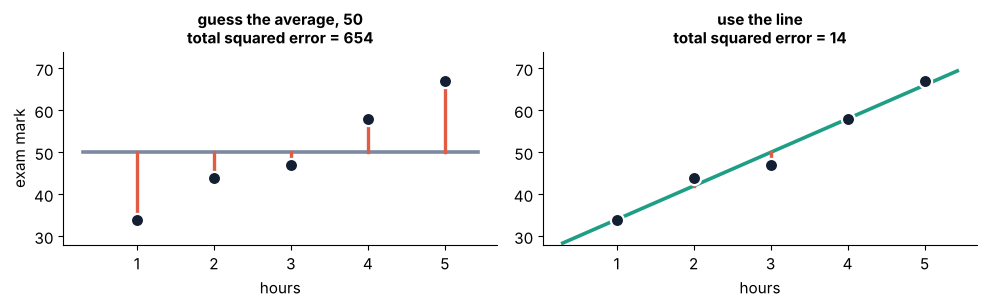

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (pred, ttl, c) in zip(axes, [(flat_guess, "guess the average, 50", "#7B8AA1"),
                                     (line(hours, 8, 26), "use the line", "#1F9E86")]):
    xs = grid[grid <= 5.5]
    ax.plot(xs, np.full_like(xs, 50.) if ttl.startswith("guess") else line(xs, 8, 26),
            color=c, lw=2.6)
    for h, m, p in zip(hours, marks, pred):
        ax.plot([h, h], [m, p], color="#E05C45", lw=2.4)
    ax.scatter(hours, marks, s=90, color="#131F33", zorder=6, edgecolor="white", lw=1.6)
    ax.set_title(f"{ttl}\ntotal squared error = {((marks - pred)**2).sum():.0f}",
                 fontweight="bold", fontsize=11)
    ax.set_xlabel("hours"); ax.set_ylim(28, 74)
axes[0].set_ylabel("exam mark")
plt.tight_layout(); plt.show()

### Reading R²

| R² | means |
|---|---|
| **1.00** | every point sits exactly on the line — *suspicious, go looking for a mistake* |
| **0.98** | our five students |
| **0.60** | a real, noisy relationship — often very useful |
| **0.00** | no better than always guessing the average |
| **below 0** | **worse** than guessing the average |

**What R² does NOT tell you:**

- that the line is the right *shape*
- that hours **cause** marks
- that the model will work on new students

It only compares your line with a flat average. Nothing more.

## 4.3 · Always look at the errors

Here is a different dataset, with 80 students.

In [28]:
rng = np.random.default_rng(340)
N = 80
cx = np.linspace(0.4, 13.6, N) + rng.normal(0, 0.12, N)
cy = (32 + 46*(1 - np.exp(-cx/3.4)) + rng.normal(0, 3.5, N)).clip(0, 100).round(0)

curved = LinearRegression().fit(cx.reshape(-1, 1), cy)
cp = curved.predict(cx.reshape(-1, 1))

print(f"slope     : {curved.coef_[0]:.3f}")
print(f"intercept : {curved.intercept_:.3f}")
print(f"R²        : {r2_score(cy, cp):.4f}    <- that looks respectable")

slope     : 2.439
intercept : 50.427
R²        : 0.7480    <- that looks respectable


R² of 0.75. Respectable. We could stop here and report it.

**Do not stop here.** Plot the errors against the input.

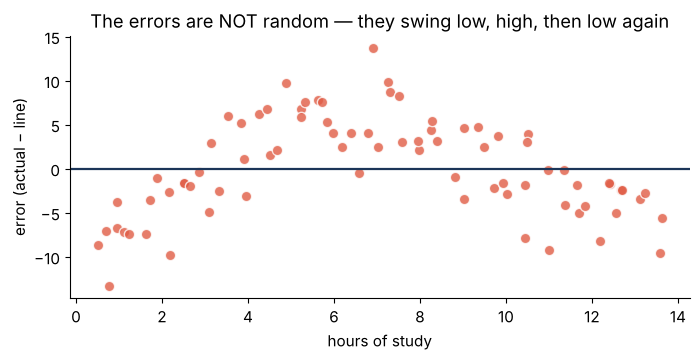

In [29]:
plt.axhline(0, color="#1B3558", lw=1.6)
plt.scatter(cx, cy - cp, s=55, color="#E05C45", alpha=0.8, edgecolor="white", lw=1)
plt.xlabel("hours of study"); plt.ylabel("error (actual − line)")
plt.title("The errors are NOT random — they swing low, high, then low again")
plt.show()

In [30]:
print("average error, by slice of the data:")
for lo, hi in [(0, 3.5), (3.5, 7), (7, 10.5), (10.5, 14)]:
    k = (cx >= lo) & (cx < hi)
    print(f"   hours {lo:>4} to {hi:<4}:  {(cy - cp)[k].mean():+6.2f}   ({k.sum()} students)")

average error, by slice of the data:
   hours    0 to 3.5 :   -4.67   (19 students)
   hours  3.5 to 7   :   +4.96   (21 students)
   hours    7 to 10.5:   +2.19   (22 students)
   hours 10.5 to 14  :   -3.54   (18 students)


### That pattern is the line telling you it is the wrong shape

Low, high, high, low. A good line scatters its errors randomly around zero; this one is
systematically wrong in a repeating way.

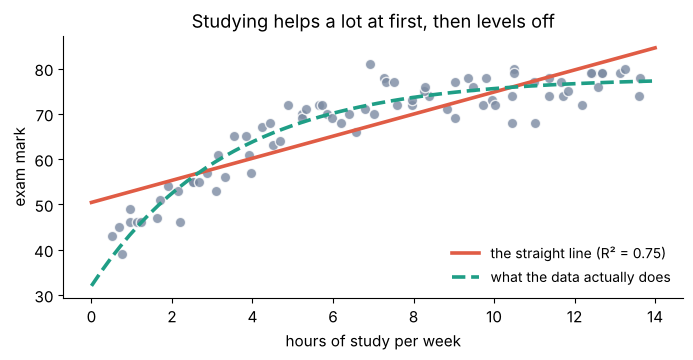

In [31]:
plt.scatter(cx, cy, s=55, color="#7B8AA1", alpha=0.8, edgecolor="white", lw=1)
xs = np.linspace(0, 14, 60)
plt.plot(xs, curved.predict(xs.reshape(-1, 1)), color="#E05C45", lw=2.6,
         label="the straight line (R² = 0.75)")
plt.plot(xs, 32 + 46*(1 - np.exp(-xs/3.4)), color="#1F9E86", lw=2.6, ls="--",
         label="what the data actually does")
plt.legend(frameon=False, fontsize=10, loc="lower right")
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title("Studying helps a lot at first, then levels off")
plt.show()

**Studying helps a lot at first and then levels off.** A straight line cannot level off,
so it under-predicts at both ends and over-predicts in the middle — exactly the pattern
the errors showed us.

The residual plot takes one line of code and it is the most useful check in regression.
Draw it every single time.

### Now compare: what a line that FITS looks like

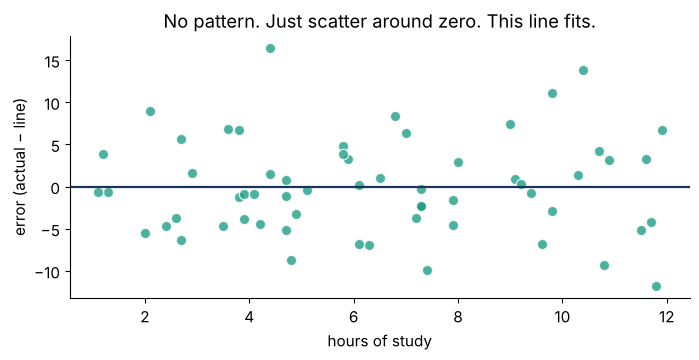

average error, by slice:
   hours   1 to 4  :   +0.09   (16 students)
   hours   4 to 7  :   +0.15   (18 students)
   hours   7 to 9  :   -1.72   (9 students)
   hours   9 to 12 :   +0.67   (17 students)


In [32]:
rng = np.random.default_rng(331)
rh = rng.uniform(1, 12, 60).round(1)
rm = (28 + 5.4*rh + rng.normal(0, 6, 60)).clip(0, 100).round(0)

good = LinearRegression().fit(rh.reshape(-1, 1), rm)
resid = rm - good.predict(rh.reshape(-1, 1))

plt.axhline(0, color="#1B3558", lw=1.6)
plt.scatter(rh, resid, s=55, color="#1F9E86", alpha=0.8, edgecolor="white", lw=1)
plt.xlabel("hours of study"); plt.ylabel("error (actual − line)")
plt.title("No pattern. Just scatter around zero. This line fits.")
plt.show()

print("average error, by slice:")
for lo, hi in [(1, 4), (4, 7), (7, 9), (9, 12)]:
    k = (rh >= lo) & (rh < hi)
    print(f"   hours {lo:>3} to {hi:<3}:  {resid[k].mean():+6.2f}   ({k.sum()} students)")

---
# Part 5 · Doing it for real

## 5.1 · The whole thing in three lines

In [33]:
model = LinearRegression().fit(hours.reshape(-1, 1), marks)

print("slope     :", model.coef_[0])
print("intercept :", model.intercept_)

slope     : 8.0
intercept : 26.0


**8.0 and 26.0** — exactly what you worked out by hand in Part 3.

The computer is not doing anything you have not already done on paper. That is worth
sitting with for a second.

| | what it does |
|---|---|
| `.fit(X, y)` | runs the formula from section 3.2 |
| `.coef_` | the slope. One per input column, so it is always a **list** |
| `.intercept_` | the intercept. A single number |
| `.predict(X)` | applies the rule to new students |

**One wrinkle:** `X` must be 2-dimensional — a table, not a flat list. That is what
`.reshape(-1, 1)` is doing. It is the single most common error beginners hit.

In [34]:
# this is the mistake everybody makes once
try:
    LinearRegression().fit(hours, marks)
except Exception as e:
    print(type(e).__name__)
    print(str(e)[:220])

ValueError
Expected 2D array, got 1D array instead:
array=[1. 2. 3. 4. 5.].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.


## 5.2 · Sixty students instead of five

In [35]:
real = pd.DataFrame({"hours": rh, "marks": rm})
real.describe().round(2)

,hours,marks
count,60.00,60.00
mean,6.39,62.38
std,3.11,17.88
min,1.10,33.00
25%,3.90,48.00
50%,6.10,63.00
75%,9.12,77.25
max,11.90,99.00


In [36]:
big = LinearRegression().fit(real[["hours"]], real["marks"])
pred = big.predict(real[["hours"]])

print(f"mark = {big.coef_[0]:.2f} × hours + {big.intercept_:.1f}")
print()
print(f"R²            : {r2_score(real.marks, pred):.4f}")
print(f"average miss  : {mean_absolute_error(real.marks, pred):.2f} marks")

mark = 5.44 × hours + 27.6

R²            : 0.8958
average miss  : 4.52 marks


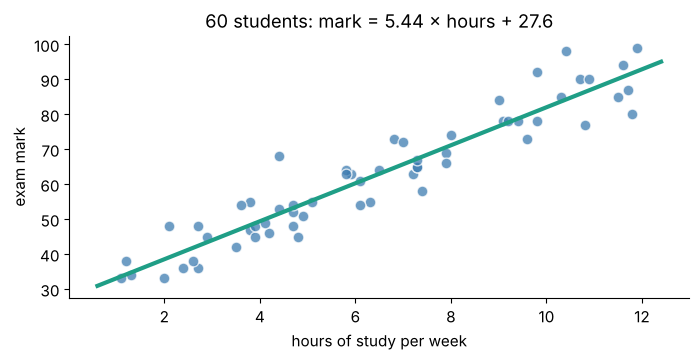

In [37]:
plt.scatter(real.hours, real.marks, s=60, color="#3E7CB1", alpha=0.75,
            edgecolor="white", lw=1)
xs = np.linspace(0.6, 12.4, 50)
plt.plot(xs, big.predict(xs.reshape(-1, 1)), color="#1F9E86", lw=3)
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title(f"60 students: mark = {big.coef_[0]:.2f} × hours + {big.intercept_:.1f}")
plt.show()

### The slope moved from 8 to 5.44

That is the real lesson of this section. **Five students was never enough to pin the
slope down.** With sixty, the answer is different — and much more trustworthy.

Our five students happened to be unusually consistent. Real data is messier, and the
honest slope is smaller.

## 5.3 · Hide some students before you fit

Same rule as Day 31. Fit on some rows, score on rows the model has never seen.

In [38]:
X_train, X_hidden, y_train, y_hidden = train_test_split(
    real[["hours"]], real["marks"], test_size=0.3, random_state=0)

split_model = LinearRegression().fit(X_train, y_train)

print(f"score on the rows it studied : {split_model.score(X_train, y_train):.4f}")
print(f"score on rows it never saw   : {split_model.score(X_hidden, y_hidden):.4f}")
print(f"the gap                      : {split_model.score(X_train, y_train) - split_model.score(X_hidden, y_hidden):.4f}")
print()
print(f"average miss on hidden rows  : {mean_absolute_error(y_hidden, split_model.predict(X_hidden)):.2f} marks")

score on the rows it studied : 0.9004
score on rows it never saw   : 0.8829
the gap                      : 0.0175

average miss on hidden rows  : 4.41 marks


### A gap of 0.017 is nothing

Compare that with Day 31, where a decision tree scored a **perfect 1.000** on the rows it
studied and then collapsed to 0.644 on new ones.

**Why the difference?** A straight line has only **two numbers** to adjust. It is almost
impossible for it to memorise 42 students with two numbers. The tree had enough freedom
to memorise every row.

That trade-off — too simple to learn the pattern, versus free enough to memorise the rows
— has a name, and it gets a whole day of its own later in the module.

## 5.4 · ⚠️ The trap: never ask about hours you never saw

In [39]:
print("hours in our data run from", real.hours.min(), "to", real.hours.max())
print()
for h in [5, 10, 25, 40]:
    inside = "inside the data" if h <= real.hours.max() else "OUTSIDE - invented"
    print(f"  {h:>3} hours a week  ->  {big.predict([[h]])[0]:>6.1f} marks    ({inside})")

hours in our data run from 1.1 to 11.9

    5 hours a week  ->    54.8 marks    (inside the data)
   10 hours a week  ->    82.0 marks    (inside the data)
   25 hours a week  ->   163.5 marks    (OUTSIDE - invented)
   40 hours a week  ->   245.1 marks    (OUTSIDE - invented)


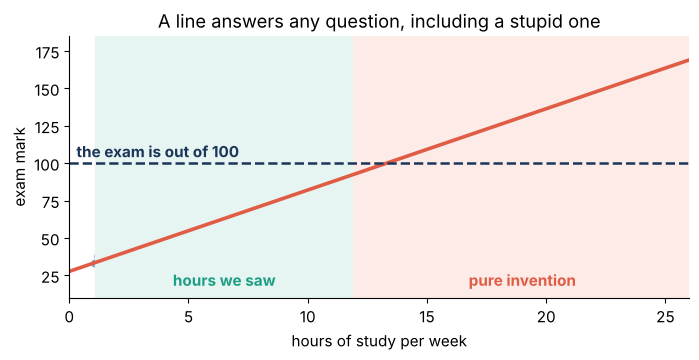

In [40]:
xs = np.linspace(0, 26, 80)
plt.plot(xs, big.predict(xs.reshape(-1, 1)), color="#E05C45", lw=2.6)
plt.scatter(real.hours, real.marks, s=45, color="#3E7CB1", alpha=0.7,
            edgecolor="white", lw=0.8)
plt.axhline(100, color="#1B3558", lw=1.8, ls="--")
plt.text(0.3, 104, "the exam is out of 100", fontweight="bold", color="#1B3558")
plt.axvspan(1.1, 11.9, color="#E6F5F1")
plt.axvspan(11.9, 26, color="#FCEBE7")
plt.text(6.5, 18, "hours we saw", ha="center", color="#1F9E86", fontweight="bold")
plt.text(19, 18, "pure invention", ha="center", color="#E05C45", fontweight="bold")
plt.ylim(10, 185); plt.xlim(0, 26)
plt.xlabel("hours of study per week"); plt.ylabel("exam mark")
plt.title("A line answers any question, including a stupid one")
plt.show()

**164 marks on a paper out of 100.**

The line does not know the exam has a ceiling. It does not know a week has 168 hours. It
knows two numbers, and it will apply them to anything you hand it.

**The rule:** a model is only trustworthy inside the range of data it saw. Outside that
range you are not predicting — you are extending a pencil mark off the edge of the page.

## 5.5 · When is a straight line the right choice?

| Use a line when | Do not use a line when |
|---|---|
| the scatter plot looks like a band going up or down | the scatter plot curves or levels off |
| you need to **explain** the result to somebody | the spread grows as x grows |
| you have few rows | a few extreme outliers are dragging it |
| you want a **baseline** for fancier models to beat | the real pattern is a step, not a slope |

**Always fit the line first anyway.** It takes ten seconds and it gives you a number
every fancier model has to beat. A gradient-boosted forest that scores 0.62 against a
straight line's 0.60 was not worth the afternoon.

## 5.6 · The five steps, every time

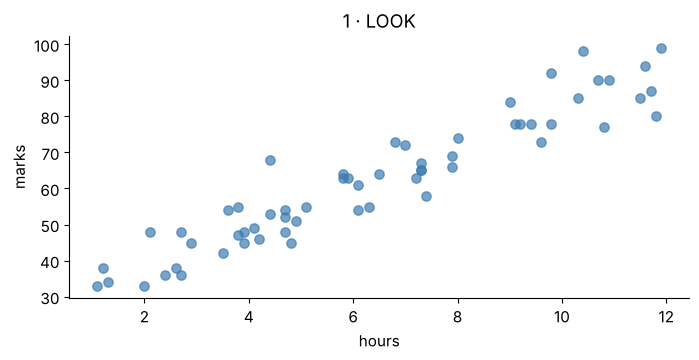

4 · READ    one extra hour is worth about 5.44 marks
5 · CHECK   R² on hidden rows: 0.8829
            average miss     : 4.41 marks


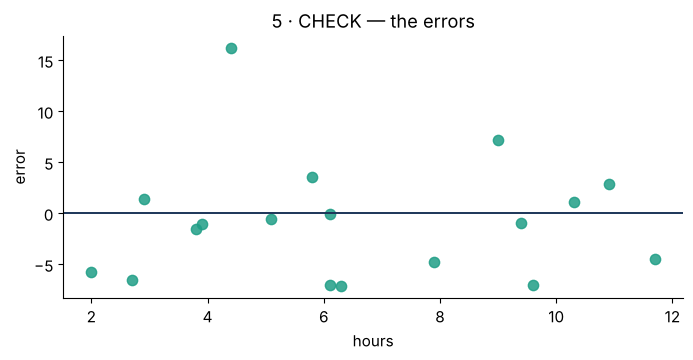

In [41]:
#  1 · LOOK   - draw the scatter before anything else
plt.scatter(real.hours, real.marks, s=45, color="#3E7CB1", alpha=0.7)
plt.xlabel("hours"); plt.ylabel("marks"); plt.title("1 · LOOK")
plt.show()

#  2 · SPLIT  - hide rows before fitting
a, b, c, d = train_test_split(real[["hours"]], real["marks"],
                              test_size=0.3, random_state=0)

#  3 · FIT
m = LinearRegression().fit(a, c)

#  4 · READ   - what do the two numbers MEAN?
print(f"4 · READ    one extra hour is worth about {m.coef_[0]:.2f} marks")

#  5 · CHECK  - score, and look at the errors
print(f"5 · CHECK   R² on hidden rows: {m.score(b, d):.4f}")
print(f"            average miss     : {mean_absolute_error(d, m.predict(b)):.2f} marks")

plt.axhline(0, color="#1B3558", lw=1.4)
plt.scatter(b["hours"], d - m.predict(b), s=55, color="#1F9E86", alpha=0.85)
plt.xlabel("hours"); plt.ylabel("error"); plt.title("5 · CHECK — the errors")
plt.show()

## 5.7 · Five mistakes everybody makes once

| # | The mistake | What you will see | The fix |
|---|---|---|---|
| 1 | Fitting without plotting first | A respectable R² on data that curves | Draw the scatter. Always |
| 2 | Quoting the intercept | "Zero hours gives 26 marks" | Check 0 is inside your data |
| 3 | Predicting outside the data | 164 marks out of 100 | Note your min and max, stay inside |
| 4 | Trusting R² on its own | A pattern hiding in the errors | Plot the errors against the input |
| 5 | Saying hours **cause** marks | A confident, unprovable claim | A line measures movement, not cause |

Number 5 deserves a paragraph. Students who study more probably also sleep better, attend
more lectures, and start revising earlier. The line cannot separate any of that. It
measures that two things **move together** — nothing else.

---

# What to remember

| | |
|---|---|
| **A line is two numbers** | slope and intercept. That is the entire model |
| **"Best" had to be defined** | adding errors gives zero for the worst line imaginable; squaring first is what makes the score mean something |
| **Least squares, literally** | every error becomes a square; the best line has the smallest total area — 14, not 104 |
| **Two routes, one answer** | a formula gives slope 8 in one calculation; gradient descent walks there in 800 steps. Only the second survives into big models |
| **R² compares with the average** | 0.979 means the line removed 97.9% of the error that guessing 50 every time would have left |
| **Look at the errors** | a pattern in the errors beats any score. And never ask the line about hours it has never seen |

---

### Tonight

19 practice questions. Part A is pen and paper — find the best line by hand, twice.
Part D hands you a model with an R² of 0.93 and asks you to prove its headline claim is
worthless.

### Next

**Day 34 — multiple linear regression.** What happens when you have more than one input
column. The maths barely changes; the picture becomes a plane.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*